# CubiCasa5k on your own floor plan image

Run this notebook with the working directory set to your CubiCasa5k clone:

```bash
cd ~/CubiCasa5k
jupyter lab
```

It needs `model_best_val_loss_var.pkl` in that folder. It does **not** need the CubiCasa5k dataset.
Set `IMG_PATH` in the "Load your image" cell, then run the cells top to bottom.

In [1]:
%matplotlib inline
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from floortrans.models import get_model
from floortrans.loaders import RotateNTurns
from floortrans.plotting import polygons_to_image, discrete_cmap
discrete_cmap()
from floortrans.post_prosessing import split_prediction, get_polygons
from mpl_toolkits.axes_grid1 import AxesGrid

WEIGHTS = 'model_best_val_loss_var.pkl'
assert os.path.exists(WEIGHTS), (
    f"{WEIGHTS} not found in {os.getcwd()}. Start Jupyter from ~/CubiCasa5k "
    "or change WEIGHTS to the full path."
)

rot = RotateNTurns()
room_classes = ["Background", "Outdoor", "Wall", "Kitchen", "Living Room", "Bed Room", "Bath", "Entry", "Railing", "Storage", "Garage", "Undefined"]
icon_classes = ["No Icon", "Window", "Door", "Closet", "Electrical Applience", "Toilet", "Sink", "Sauna Bench", "Fire Place", "Bathtub", "Chimney"]
n_rooms = len(room_classes)
n_icons = len(icon_classes)

# Setup model (CPU only)
model = get_model('hg_furukawa_original', 51)

n_classes = 44
split = [21, 12, 11]
model.conv4_ = torch.nn.Conv2d(256, n_classes, bias=True, kernel_size=1)
model.upsample = torch.nn.ConvTranspose2d(n_classes, n_classes, kernel_size=4, stride=4)
checkpoint = torch.load(WEIGHTS, map_location='cpu', weights_only=False)

model.load_state_dict(checkpoint['model_state'])
model.eval()
model.cpu()
print("Model loaded.")

/home/eightfive/CubiCasa5k/floortrans/plotting.py:612: UserWarning: Overwriting the cmap 'rooms_furu' that was already in the registry.
  matplotlib.colormaps.register(cmap=cmap3, force=True)


Model loaded.


## Load your image

Use a clean, top-down floor plan (an architectural drawing). Angled photos and heavily
annotated listing images tend to give poor results.

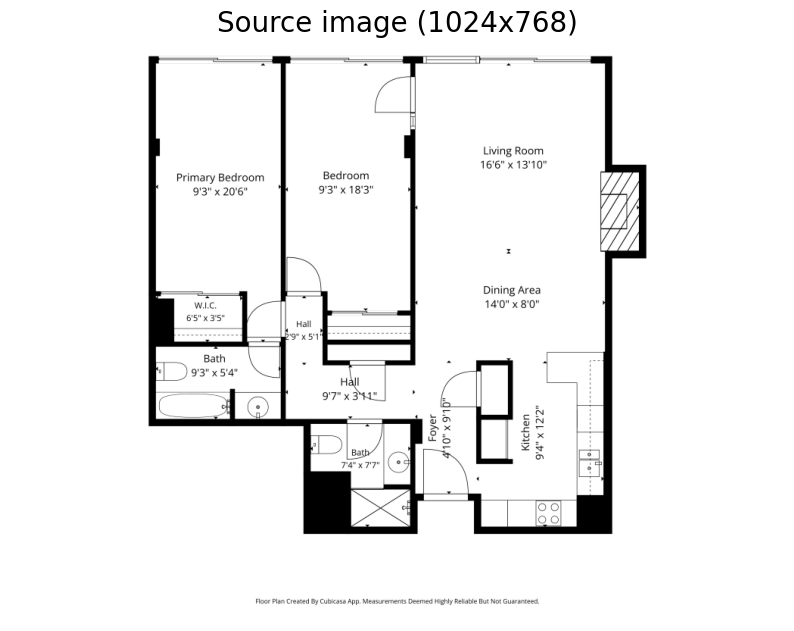

In [2]:
IMG_PATH = 'fp1.jpg'   # <-- change this (relative to the working directory, or absolute)
MAX_SIDE = 1024                   # larger images are shrunk to this; lower it (768, 512) if slow or out of RAM

raw = cv2.imread(IMG_PATH, cv2.IMREAD_UNCHANGED)
assert raw is not None, f"Could not read {IMG_PATH} from {os.getcwd()}"

# Handle grayscale / transparent PNGs: flatten everything onto white
if raw.ndim == 2:
    raw = cv2.cvtColor(raw, cv2.COLOR_GRAY2BGR)
elif raw.shape[2] == 4:
    alpha = raw[:, :, 3:4].astype(np.float32) / 255.0
    raw = (raw[:, :, :3] * alpha + 255 * (1 - alpha)).astype(np.uint8)

rgb = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)

h0, w0 = rgb.shape[:2]
scale = min(1.0, MAX_SIDE / max(h0, w0))
if scale < 1.0:
    rgb = cv2.resize(rgb, (int(w0 * scale), int(h0 * scale)), interpolation=cv2.INTER_AREA)

height, width = rgb.shape[:2]
img_size = (height, width)

# Same normalization the dataset loader uses: [0,255] -> [-1,1], channels first
image = torch.from_numpy(np.moveaxis(2 * (rgb / 255.0) - 1, -1, 0)).float().unsqueeze(0)

np_img = np.moveaxis(image[0].numpy(), 0, -1) / 2 + 0.5
plt.figure(figsize=(10, 10))
plt.title(f'Source image ({width}x{height})', fontsize=20)
plt.axis('off')
plt.imshow(np_img)
plt.show()

## Run the model

This runs the network four times (one per 90-degree rotation) and averages the results.
On CPU this can take from several seconds to a minute or so.

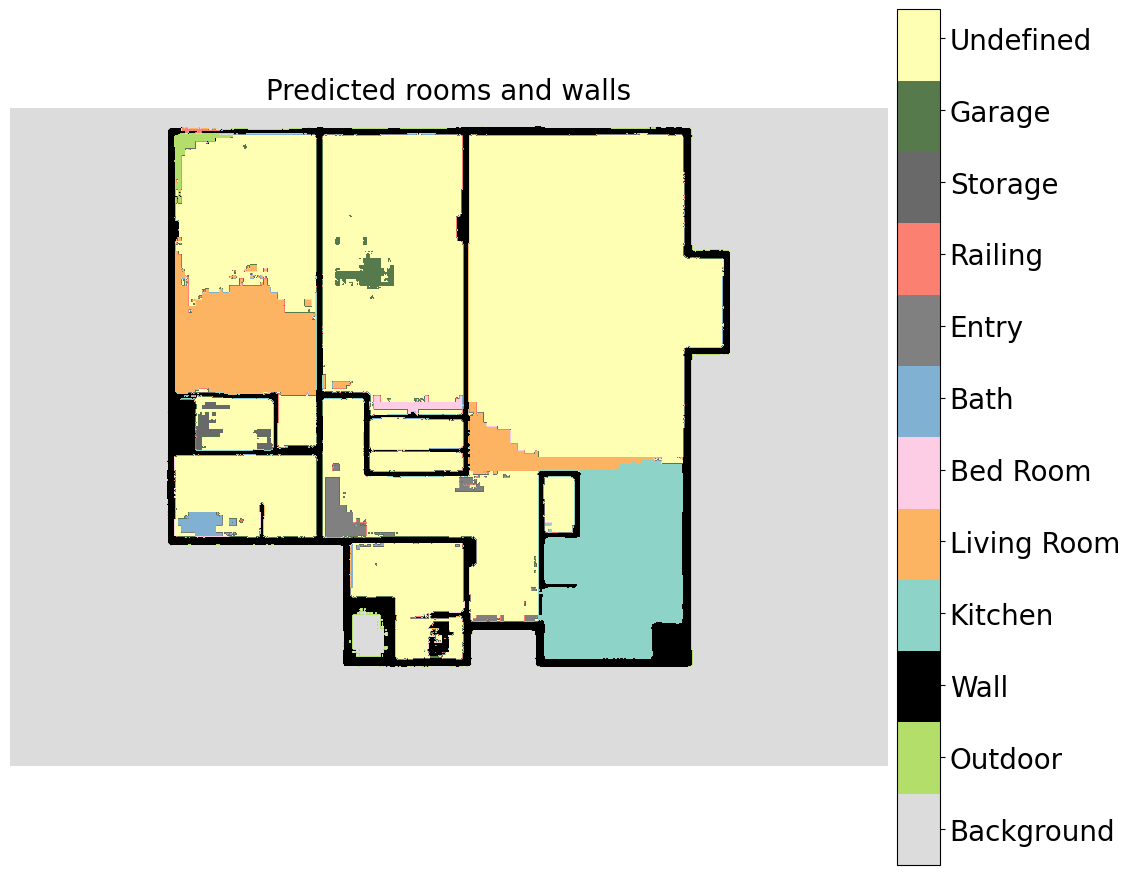

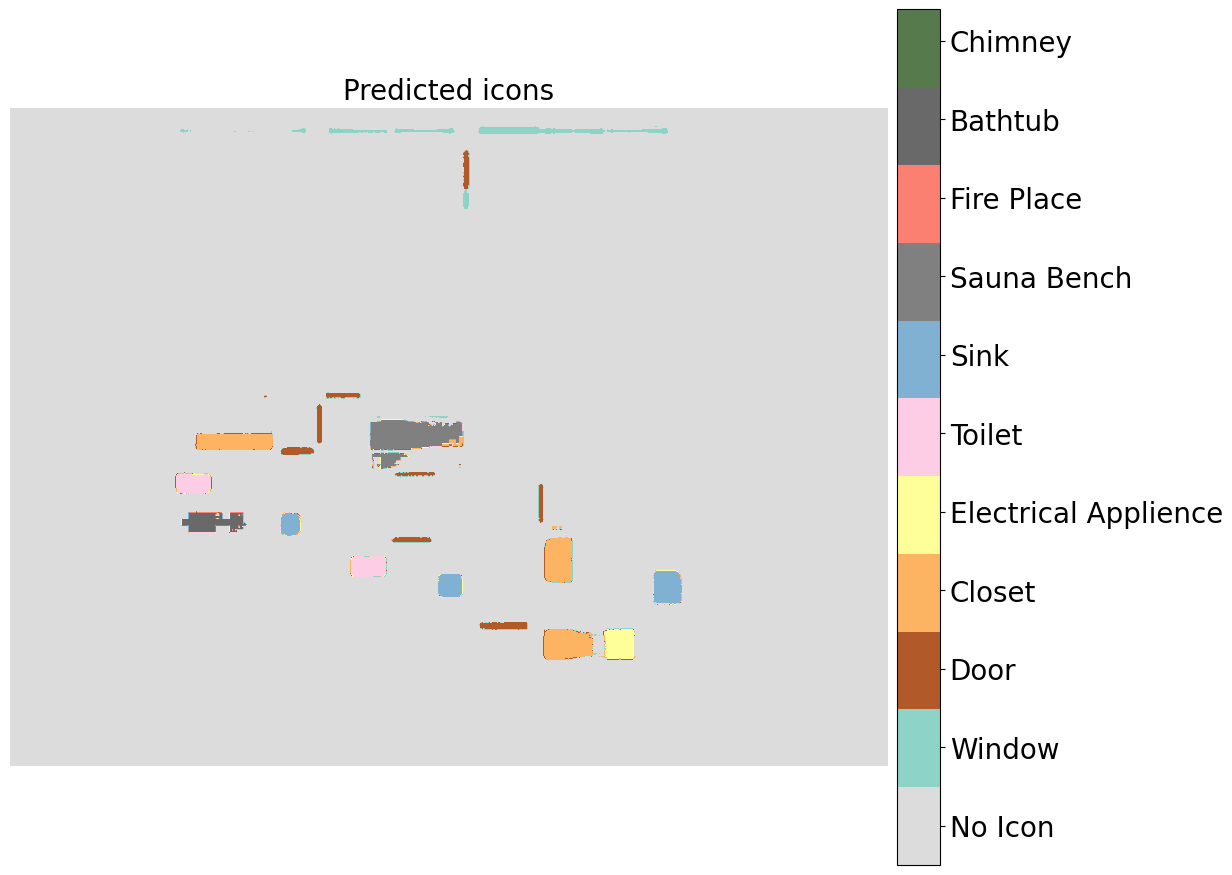

In [3]:
with torch.no_grad():
    rotations = [(0, 0), (1, -1), (2, 2), (-1, 1)]
    prediction = torch.zeros([len(rotations), n_classes, height, width])
    for i, (forward, back) in enumerate(rotations):
        rot_image = rot(image, 'tensor', forward)   # rotate the image
        pred = model(rot_image)
        pred = rot(pred, 'tensor', back)            # rotate the prediction back
        pred = rot(pred, 'points', back)            # fix the heatmaps
        pred = F.interpolate(pred, size=(height, width), mode='bilinear', align_corners=True)
        prediction[i] = pred[0]

prediction = torch.mean(prediction, 0, True)

rooms_pred = F.softmax(prediction[0, 21:21+12], 0).cpu().data.numpy()
rooms_pred = np.argmax(rooms_pred, axis=0)

icons_pred = F.softmax(prediction[0, 21+12:], 0).cpu().data.numpy()
icons_pred = np.argmax(icons_pred, axis=0)

plt.figure(figsize=(12, 12))
ax = plt.subplot(1, 1, 1)
ax.axis('off')
plt.title('Predicted rooms and walls', fontsize=20)
rseg = ax.imshow(rooms_pred, cmap='rooms', vmin=0, vmax=n_rooms-0.1)
cbar = plt.colorbar(rseg, ticks=np.arange(n_rooms) + 0.5, fraction=0.046, pad=0.01)
cbar.ax.set_yticklabels(room_classes, fontsize=20)
plt.show()

plt.figure(figsize=(12, 12))
ax = plt.subplot(1, 1, 1)
ax.axis('off')
plt.title('Predicted icons', fontsize=20)
iseg = ax.imshow(icons_pred, cmap='icons', vmin=0, vmax=n_icons-0.1)
cbar = plt.colorbar(iseg, ticks=np.arange(n_icons) + 0.5, fraction=0.046, pad=0.01)
cbar.ax.set_yticklabels(icon_classes, fontsize=20)
plt.show()

## Post-processing: turn the raw prediction into polygons

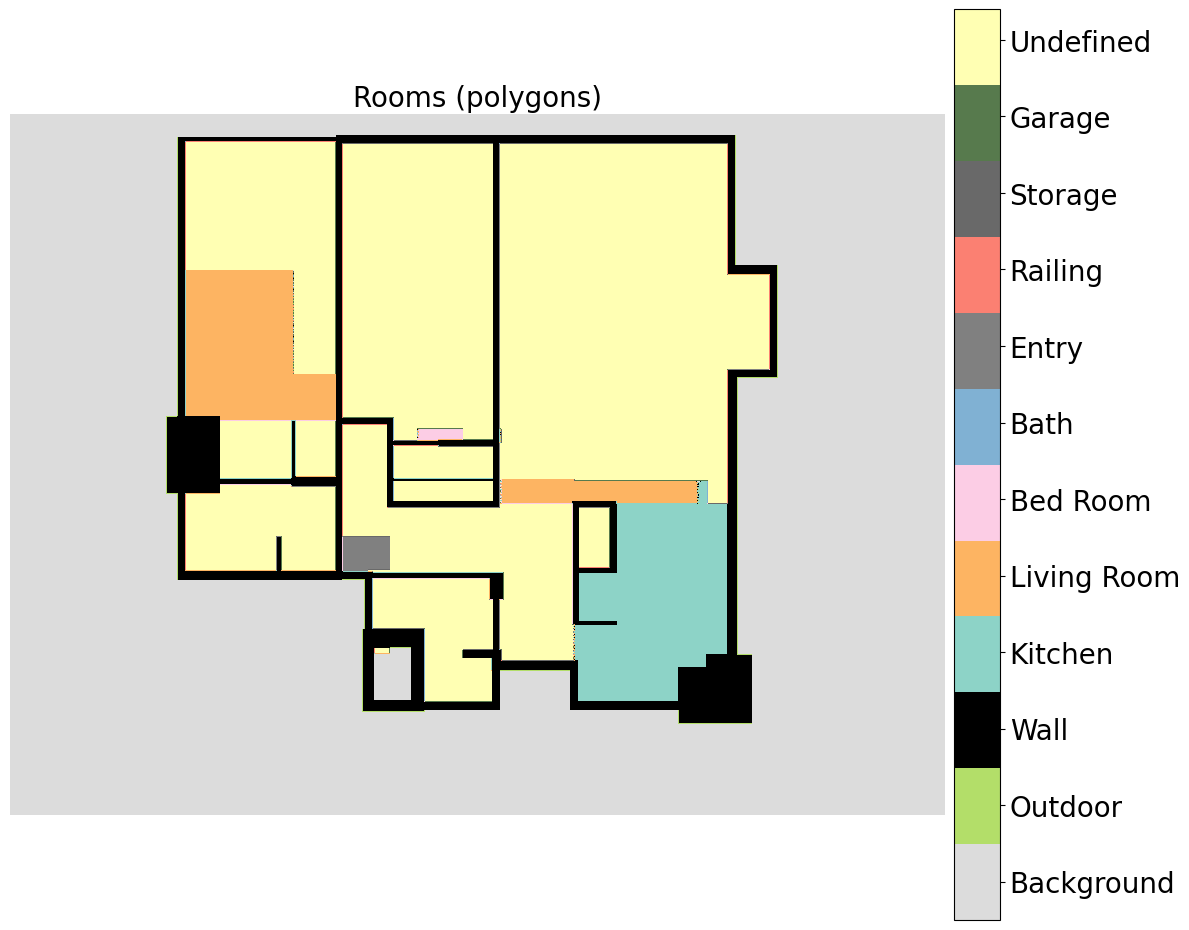

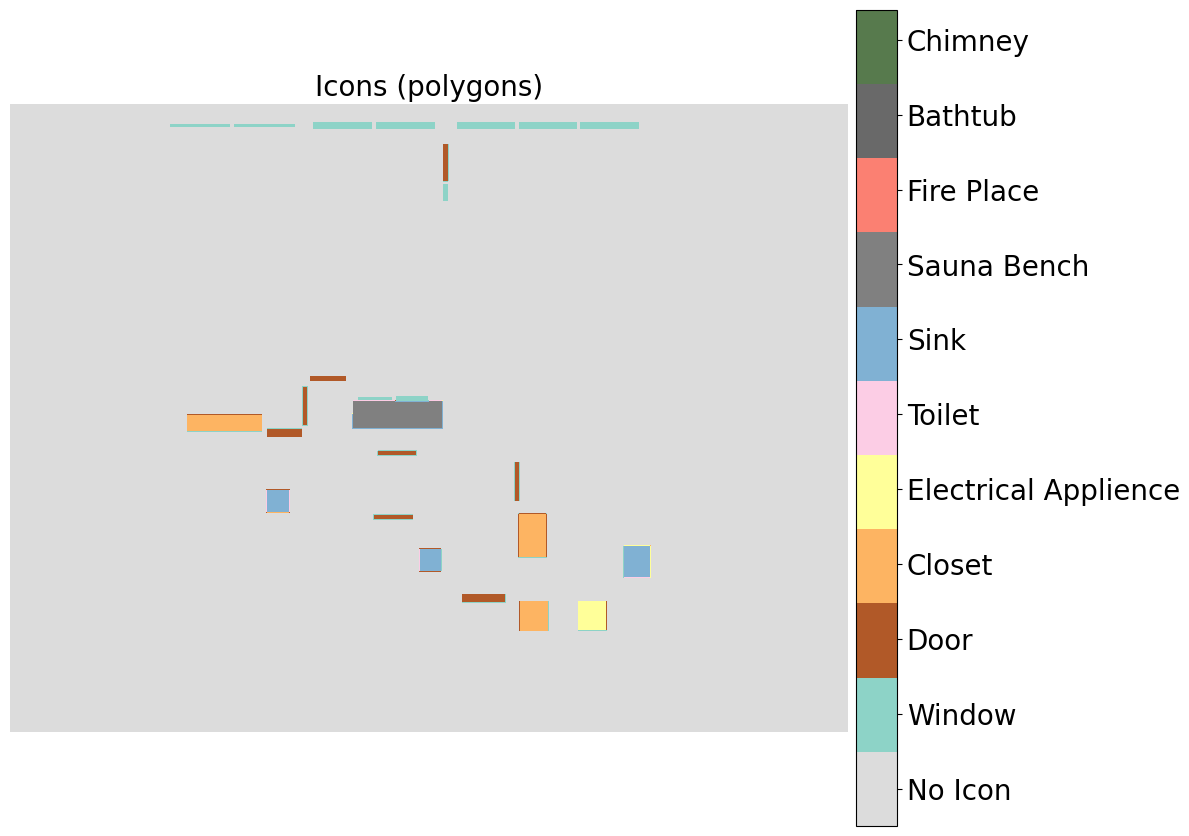

In [4]:
heatmaps, rooms, icons = split_prediction(prediction, img_size, split)
polygons, types, room_polygons, room_types = get_polygons((heatmaps, rooms, icons), 0.2, [1, 2])

pol_room_seg, pol_icon_seg = polygons_to_image(polygons, types, room_polygons, room_types, height, width)

plt.figure(figsize=(12, 12))
ax = plt.subplot(1, 1, 1)
ax.axis('off')
plt.title('Rooms (polygons)', fontsize=20)
rseg = ax.imshow(pol_room_seg, cmap='rooms', vmin=0, vmax=n_rooms-0.1)
cbar = plt.colorbar(rseg, ticks=np.arange(n_rooms) + 0.5, fraction=0.046, pad=0.01)
cbar.ax.set_yticklabels(room_classes, fontsize=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 12))
ax = plt.subplot(1, 1, 1)
ax.axis('off')
plt.title('Icons (polygons)', fontsize=20)
iseg = ax.imshow(pol_icon_seg, cmap='icons', vmin=0, vmax=n_icons-0.1)
cbar = plt.colorbar(iseg, ticks=np.arange(n_icons) + 0.5, fraction=0.046, pad=0.01)
cbar.ax.set_yticklabels(icon_classes, fontsize=20)
plt.tight_layout()
plt.show()

## Raw prediction vs. polygonized result

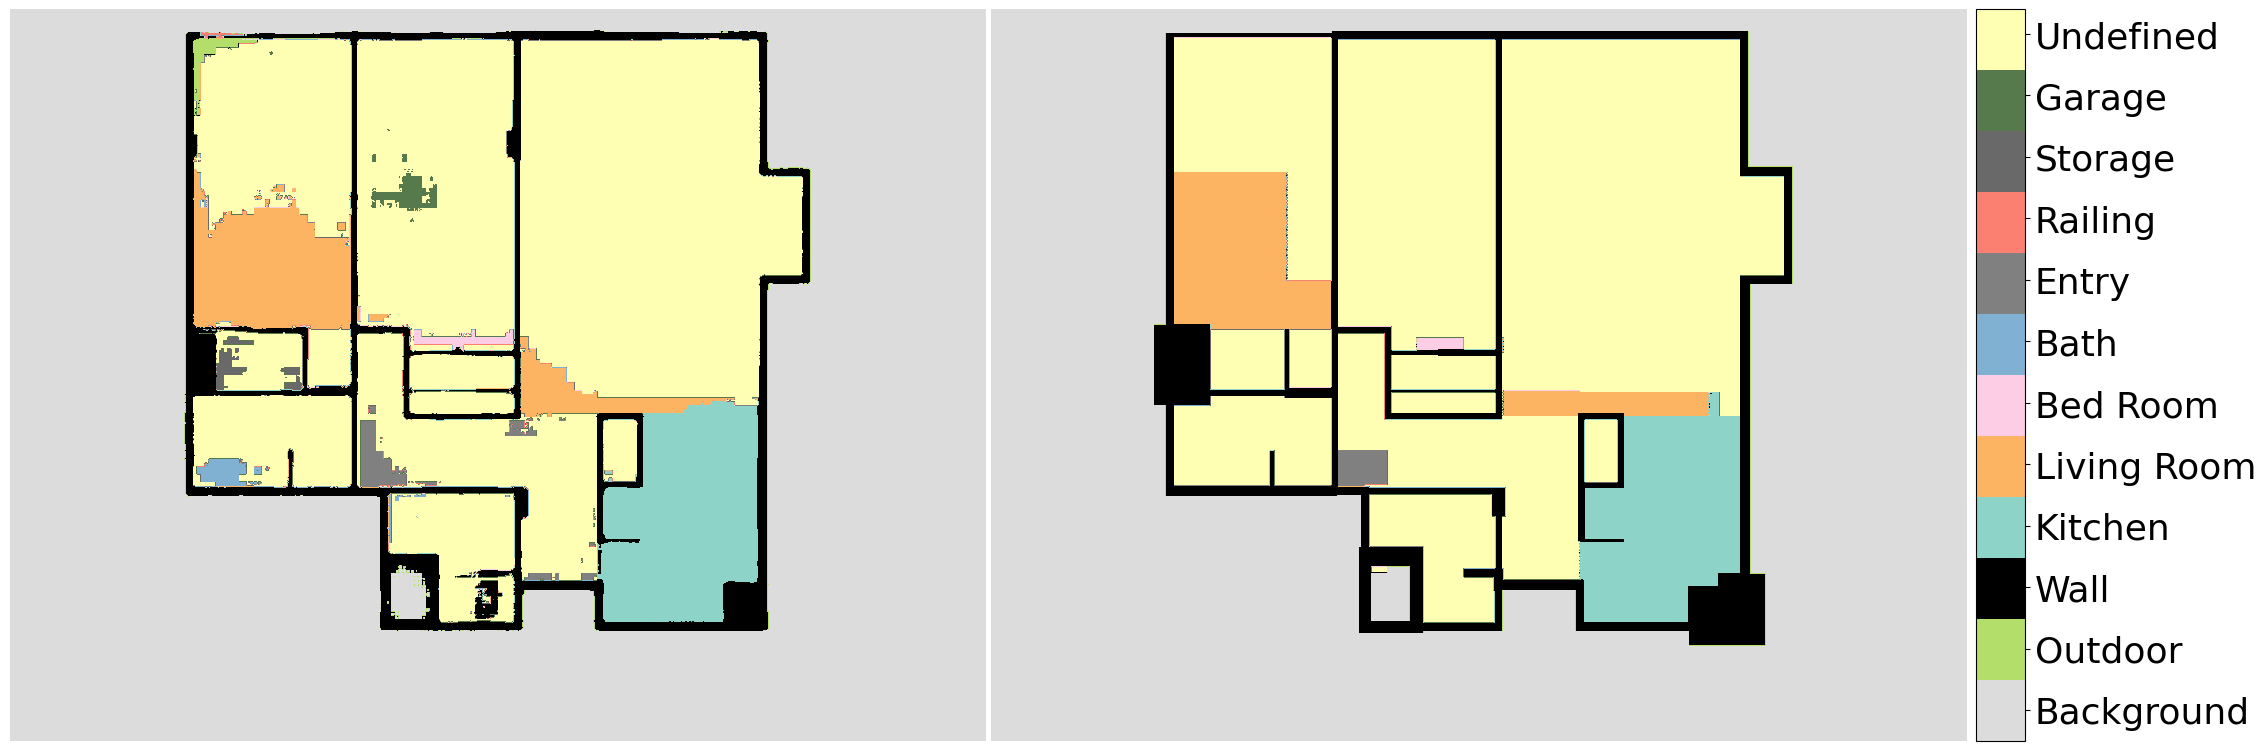

In [5]:
fig = plt.figure(figsize=(26, 12))
grid = AxesGrid(fig, 111, nrows_ncols=(1, 2), axes_pad=0.05,
                cbar_mode='single', cbar_location='right', cbar_pad=0.1)
images = [rooms_pred, pol_room_seg]
for i, ax in enumerate(grid):
    ax.set_axis_off()
    im = ax.imshow(images[i], cmap='rooms', vmin=0, vmax=n_rooms-0.1)
cbar = ax.cax.colorbar(im, ticks=np.arange(n_rooms) + 0.5)
cbar.ax.set_yticklabels(room_classes, fontsize=26)
plt.show()

## The data your app will want

`room_polygons` and `room_types` hold the room shapes and their class IDs;
`polygons` and `types` hold walls, doors and windows.

In [6]:
print(f"Image size used: {width} x {height} px")
print(f"Rooms found: {len(room_polygons)}")
print(f"Wall/opening polygons: {len(polygons)}")

# Peek at the structure so you know what to export for your app
if len(room_types):
    print("room_types[0]:", room_types[0])
    print("room_polygons[0] type:", type(room_polygons[0]))
if len(types):
    print("types[0]:", types[0])
    print("polygons[0] type:", type(polygons[0]))

Image size used: 1024 x 768 px
Rooms found: 11
Wall/opening polygons: 88
room_types[0]: {'type': 'room', 'class': 1}
room_polygons[0] type: <class 'shapely.geometry.collection.GeometryCollection'>
types[0]: {'type': 'wall', 'class': 2}
polygons[0] type: <class 'numpy.ndarray'>


In [10]:
import json

def polys_of(g):
    """Return a list of point-lists, one per polygon piece inside g."""
    if hasattr(g, "is_empty") and g.is_empty:
        return []
    if hasattr(g, "geoms"):                      # Multi* or GeometryCollection
        out = []
        for sub in g.geoms:
            out += polys_of(sub)
        return out
    if hasattr(g, "exterior"):                   # a normal shapely Polygon
        return [np.asarray(g.exterior.coords, dtype=float).round(2).tolist()]
    if hasattr(g, "coords"):                     # stray LineString / Point, skip
        return []
    return [np.asarray(g, dtype=float).round(2).tolist()]   # numpy array / list

walls, openings = [], []
for poly, t in zip(polygons, types):
    for pts in polys_of(poly):
        entry = {"points": pts}
        if t["type"] == "wall":
            walls.append(entry)
        elif t["type"] == "icon" and icon_classes[t["class"]] in ("Window", "Door"):
            entry["kind"] = icon_classes[t["class"]].lower()
            openings.append(entry)

rooms = []
for p, t in zip(room_polygons, room_types):
    for pts in polys_of(p):
        rooms.append({"points": pts, "type": room_classes[t["class"]]})

out = {
    "source_image": IMG_PATH,
    "width_px": int(width),
    "height_px": int(height),
    "resize_factor": float(scale),
    "walls": walls,
    "openings": openings,
    "rooms": rooms,
}

with open("plan1_output.json", "w") as f:
    json.dump(out, f)

cv2.imwrite("plan1_resized.png", cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))

print(len(walls), "walls,", len(openings), "openings,", len(rooms), "rooms")

61 walls, 18 openings, 8 rooms


In [11]:
import cv2, re, json, numpy as np, pytesseract

img = cv2.imread("plan1_resized.png")
UP = 3                                            # enlarge so small text is readable
big = cv2.resize(img, None, fx=UP, fy=UP, interpolation=cv2.INTER_CUBIC)
gray = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY)

# 1) read every word, with its position
d = pytesseract.image_to_data(gray, config="--psm 11",
                              output_type=pytesseract.Output.DICT)
words = []
for i, t in enumerate(d["text"]):
    if t.strip() and float(d["conf"][i]) > 0:
        words.append(dict(text=t, x=d["left"][i], y=d["top"][i],
                          w=d["width"][i], h=d["height"][i]))

# 2) glue neighbouring words on the same row back into lines
words.sort(key=lambda w: w["x"])
lines = []
for w in words:
    cy = w["y"] + w["h"] / 2
    for ln in lines:
        lcy = ln["y"] + ln["h"] / 2
        gap = w["x"] - (ln["x"] + ln["w"])
        if abs(cy - lcy) < 0.6 * max(w["h"], ln["h"]) and -5 < gap < 0.8 * max(w["h"], ln["h"]):
            ln["text"] += " " + w["text"]
            ln["w"] = w["x"] + w["w"] - ln["x"]
            ln["y"] = min(ln["y"], w["y"])
            ln["h"] = max(ln["h"], w["h"])
            break
    else:
        lines.append(dict(w))

# 3) understand text like  14'-6" x 18'0"
LEN = r"(\d+)\s*'\s*-?\s*(?:(\d{1,2}(?:\.\d+)?)\s*\"?)?"
DIM = re.compile(LEN + r"\s*[xX×]\s*" + LEN)

def clean(s):
    for a in "’‘′`´":
        s = s.replace(a, "'")
    for a in "”“″":
        s = s.replace(a, '"')
    return s.replace("''", '"')

def feet(ft, inch):
    return int(ft) + (float(inch) / 12 if inch else 0)

found = []
for ln in lines:
    m = DIM.search(clean(ln["text"]))
    if m:
        a = feet(m.group(1), m.group(2))
        b = feet(m.group(3), m.group(4))
        found.append(dict(text=ln["text"], a_ft=a, b_ft=b,
                          cx=(ln["x"] + ln["w"] / 2) / UP,
                          cy=(ln["y"] + ln["h"] / 2) / UP,
                          box=[ln["x"] / UP, ln["y"] / UP, ln["w"] / UP, ln["h"] / UP]))

# 4) draw what was found, so you can check by eye
check = img.copy()
for f in found:
    x, y, w, h = [int(v) for v in f["box"]]
    cv2.rectangle(check, (x, y), (x + w, y + h), (0, 0, 255), 2)
cv2.imwrite("plan1_text_check.png", check)

with open("plan1_measurements.json", "w") as fh:
    json.dump(found, fh, indent=1)

print(len(lines), "text lines read,", len(found), "measurements understood")
for f in found:
    print(repr(f["text"]), "->", round(f["a_ft"], 2), "x", round(f["b_ft"], 2), "ft")

33 text lines read, 5 measurements understood
'> 9\'3" x 5\'4" Cy' -> 9.25 x 5.33 ft
'9\'3" x 20\'6"' -> 9.25 x 20.5 ft
'9\'3" x 18\'3"' -> 9.25 x 18.25 ft
'16\'6" x 13\'10"' -> 16.5 x 13.83 ft
'14\'0" x 8\'0"' -> 14.0 x 8.0 ft


In [12]:
import json, cv2, numpy as np

raw  = json.load(open("plan1_output.json"))
meas = json.load(open("plan1_measurements.json"))
img  = cv2.imread("plan1_resized.png")
H, W = img.shape[:2]

# 1) Wall mask: walls + doors + windows filled in (openings close the gaps between rooms)
mask = np.zeros((H, W), np.uint8)
for item in raw["walls"] + raw["openings"]:
    cv2.fillPoly(mask, [np.round(np.array(item["points"])).astype(np.int32)], 255)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))  # seal hairline gaps

# 2) Empty space -> connected pockets = enclosed regions
free = (mask == 0).astype(np.uint8)
n, labels, stats, _ = cv2.connectedComponentsWithStats(free, connectivity=4)

def touches_border(i):
    x, y, w, h, _ = stats[i]
    return x == 0 or y == 0 or x + w >= W or y + h >= H

# 3) Which region does each measurement label sit in?
region_of = {}
for k, m in enumerate(meas):
    r = labels[int(m["cy"]), int(m["cx"])]
    region_of[k] = r

counts = {}
for r in region_of.values():
    counts[r] = counts.get(r, 0) + 1

estimates, dbg = [], img.copy()
for k, m in enumerate(meas):
    r = region_of[k]
    if r == 0 or touches_border(r):
        print("label not inside an enclosed room:", repr(m["text"])); continue
    if counts[r] > 1:
        print("region holds several labels (open plan?), skipping:", repr(m["text"])); continue

    cnts, _ = cv2.findContours((labels == r).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c = max(cnts, key=cv2.contourArea)
    (cx, cy), (rw, rh), _ = cv2.minAreaRect(c)
    area = cv2.contourArea(c)
    boxiness = area / (rw * rh)
    short, long_ = min(rw, rh), max(rw, rh)
    cv2.drawContours(dbg, [c], -1, (0, 160, 0), 2)

    if boxiness < 0.85:
        print(f"skipping irregular room (boxiness {boxiness:.2f}):", repr(m["text"])); continue

    a, b = sorted([m["a_ft"], m["b_ft"]])
    es, el = short / a, long_ / b
    estimates.append((es, el))
    print(f'{m["text"]!r:24} boxiness {boxiness:.2f} -> {es:6.2f} (short)  {el:6.2f} (long)  px/ft')

cv2.imwrite("plan1_regions_check.png", dbg)

vals = np.array([v for e in estimates for v in e])
if len(vals) == 0:
    raise SystemExit("No usable rooms, so fall back to a hand-typed scale.")

med = np.median(vals)
good = vals[np.abs(vals - med) / med < 0.15]
ppf = float(np.median(good))
spread = float(good.std() / ppf)
print(f"\nused {len(good)} of {len(vals)} estimates")
print(f"PIXELS_PER_FOOT = {ppf:.2f}   (spread {spread*100:.1f}%)")

json.dump({"pixels_per_foot": ppf, "spread": spread, "n_used": int(len(good))},
          open("plan1_scale.json", "w"))

'> 9\'3" x 5\'4" Cy'     boxiness 0.95 ->  17.44 (short)   17.73 (long)  px/ft
'9\'3" x 20\'6"'         boxiness 0.95 ->  17.73 (short)   17.95 (long)  px/ft
'9\'3" x 18\'3"'         boxiness 0.97 ->  17.73 (short)   17.81 (long)  px/ft
region holds several labels (open plan?), skipping: '16\'6" x 13\'10"'
region holds several labels (open plan?), skipping: '14\'0" x 8\'0"'

used 6 of 6 estimates
PIXELS_PER_FOOT = 17.73   (spread 0.9%)


In [16]:
import json, cv2, numpy as np

PIXELS_PER_FOOT = json.load(open("plan1_scale.json"))["pixels_per_foot"]    # None = leave in pixels. Tesseract will set this later.
CEILING_FT = 8

def long_axis(points):
    """Rectangle -> (x1,y1,x2,y2, thickness, center, length)"""
    box = cv2.boxPoints(cv2.minAreaRect(np.array(points, dtype=np.float32)))
    sides = [(box[i], box[(i+1) % 4]) for i in range(4)]
    lens = [np.linalg.norm(a - b) for a, b in sides]
    order = np.argsort(lens)                      # two shortest sides first
    s1, s2 = sides[order[0]], sides[order[1]]
    p1 = (s1[0] + s1[1]) / 2
    p2 = (s2[0] + s2[1]) / 2
    length = float(np.linalg.norm(p1 - p2))
    thickness = float(lens[order[0]])
    return p1, p2, thickness, (p1 + p2) / 2, length

with open("plan1_output.json") as f:
    raw = json.load(f)

walls = []
for i, w in enumerate(raw["walls"]):
    p1, p2, thick, _, length = long_axis(w["points"])
    if length < 5:                                # tiny specks
        continue
    walls.append({"id": i, "x1": p1[0], "y1": p1[1], "x2": p2[0], "y2": p2[1],
                  "thickness": thick})

def attach(center, width, kind):
    best, best_d, best_t = None, 1e9, 0
    for w in walls:
        a = np.array([w["x1"], w["y1"]]); b = np.array([w["x2"], w["y2"]])
        ab = b - a
        t = np.clip(np.dot(center - a, ab) / np.dot(ab, ab), 0, 1)
        d = np.linalg.norm(center - (a + t * ab))
        if d < best_d:
            best, best_d, best_t = w, d, t
    L = np.hypot(best["x2"] - best["x1"], best["y2"] - best["y1"])
    return {"wall": best["id"], "type": kind,
            "position": float(best_t * L), "width": float(width)}

openings = []
for o in raw["openings"]:
    _, _, _, c, length = long_axis(o["points"])
    openings.append(attach(c, length, o["kind"]))

clean = {"ceiling_height": CEILING_FT, "units": "pixels",
         "walls": walls, "openings": openings}

if PIXELS_PER_FOOT:                               # convert to feet
    s = 1 / PIXELS_PER_FOOT
    for w in clean["walls"]:
        for k in ("x1", "y1", "x2", "y2", "thickness"):
            w[k] *= s
    for o in clean["openings"]:
        o["position"] *= s; o["width"] *= s
    clean["units"] = "feet"

with open("plan1_clean.json", "w") as f:
    json.dump(clean, f, indent=1)
print(len(walls), "walls,", len(openings), "openings,", clean["units"])

61 walls, 18 openings, feet
